# Retorno por episodio y escenario — DQN v5

Cuatro gráficos del retorno de entrenamiento, separados por el campo `scenario`
de `training_history.csv`, la misma fuente de `figures/training.png`.
No se vuelve a entrenar el agente. Requiere pandas, Matplotlib e ipykernel.

Se conserva el **número global del episodio**: los escenarios se intercalan durante
el entrenamiento. La línea representa una media móvil por escenario y el sombreado muestra
su dispersión local (±1 desviación estándar).

**Validación:** `validation_return` es la media de los cuatro escenarios en cada
evaluación greedy (ver `train_agent` en `../input/main.ipynb`); el CSV no guarda
esos retornos separados. Por ello no se presenta como validación de un escenario.


## 1. Configuración y fuente


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
np.random.seed(42)
WINDOW = 15  # Número de episodios del mismo escenario por ventana.
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})

# Permite ejecutar desde outputs/ o desde la raíz del repositorio.
output_dir = Path.cwd()
if not (output_dir / "training_history.csv").is_file():
    output_dir = output_dir / "kaggle/dqn-dummy/v5/outputs"
csv_path = output_dir / "training_history.csv"
history = pd.read_csv(csv_path)
print(f"Fuente: {csv_path.resolve()}")


Fuente: C:\Users\jeffr\GitHub\tesis-darl\kaggle\dqn-dummy\v5\outputs\training_history.csv


## 2. Comprobar la separación

Los escenarios disponibles son estable (`stable`), deriva de covariables
(`covariate`), deriva de concepto (`concept`) y deriva combinada (`combined`).
No existe un escenario llamado «Defer» en este CSV. Por ejemplo, `stable`
corresponde a los episodios 1, 8, 15, 22, …; el episodio 7 es `combined`.


In [ ]:
scenario_labels = {
    "stable": "Estable (stable)",
    "covariate": "Deriva de covariables (covariate)",
    "concept": "Deriva de concepto (concept)",
    "combined": "Deriva combinada (combined)",
}
required = {"episode", "scenario", "train_return"}
assert required.issubset(history.columns), "Faltan columnas requeridas."
assert set(history["scenario"]) == set(scenario_labels), "Escenarios inesperados."
assert history["episode"].is_unique, "Hay episodios duplicados."
assert np.isfinite(history[["episode", "train_return"]].to_numpy()).all()
history = history.sort_values("episode")
groups = {name: history.loc[history["scenario"].eq(name)] for name in scenario_labels}
assert sum(len(rows) for rows in groups.values()) == len(history)

summary = pd.DataFrame(
    [
        {
            "Escenario": scenario_labels[name],
            "Episodios": len(rows),
            "Primeros episodios": ", ".join(rows["episode"].head(6).astype(str)),
            "Retorno medio": rows["train_return"].mean(),
        }
        for name, rows in groups.items()
    ]
)
display(summary.round(3))
print(f"{len(history)} episodios asignados una sola vez a su escenario.")

,Escenario,Episodios,Primeros episodios,Retorno medio
0,Estable (stable),143,"1, 8, 15, 22, 29, 36",15.867
1,Deriva de covariables (covariate),286,"2, 5, 9, 12, 16, 19",15.226
2,Deriva de concepto (concept),286,"3, 6, 10, 13, 17, 20",15.953
3,Deriva combinada (combined),285,"4, 7, 11, 14, 18, 21",15.248


1000 episodios asignados una sola vez a su escenario.


## 3. Cuatro gráficos de retorno

Los paneles comparten las escalas horizontal y vertical para facilitar la
comparación. El retorno es la suma de recompensas del episodio, sin descuento,
tal como se guardó en `train_return`.

La línea usa la **media móvil de los últimos `WINDOW = 15` episodios del mismo
escenario**, incluido el actual. El fondo sombreado es **media ±1 desviación
estándar poblacional** (`ddof=0`) de esa misma ventana; muestra dispersión de los
retornos, no un intervalo de confianza ni el rango completo de los picos.
Al inicio se usan los episodios disponibles (`min_periods=1`); en el primer punto
la banda tiene ancho cero. No se mezclan escenarios ni se usan episodios futuros.
Como los escenarios tienen frecuencias distintas, 15 observaciones abarcan
distintos intervalos del eje de episodios globales. Puedes cambiar `WINDOW`
en la celda de configuración.


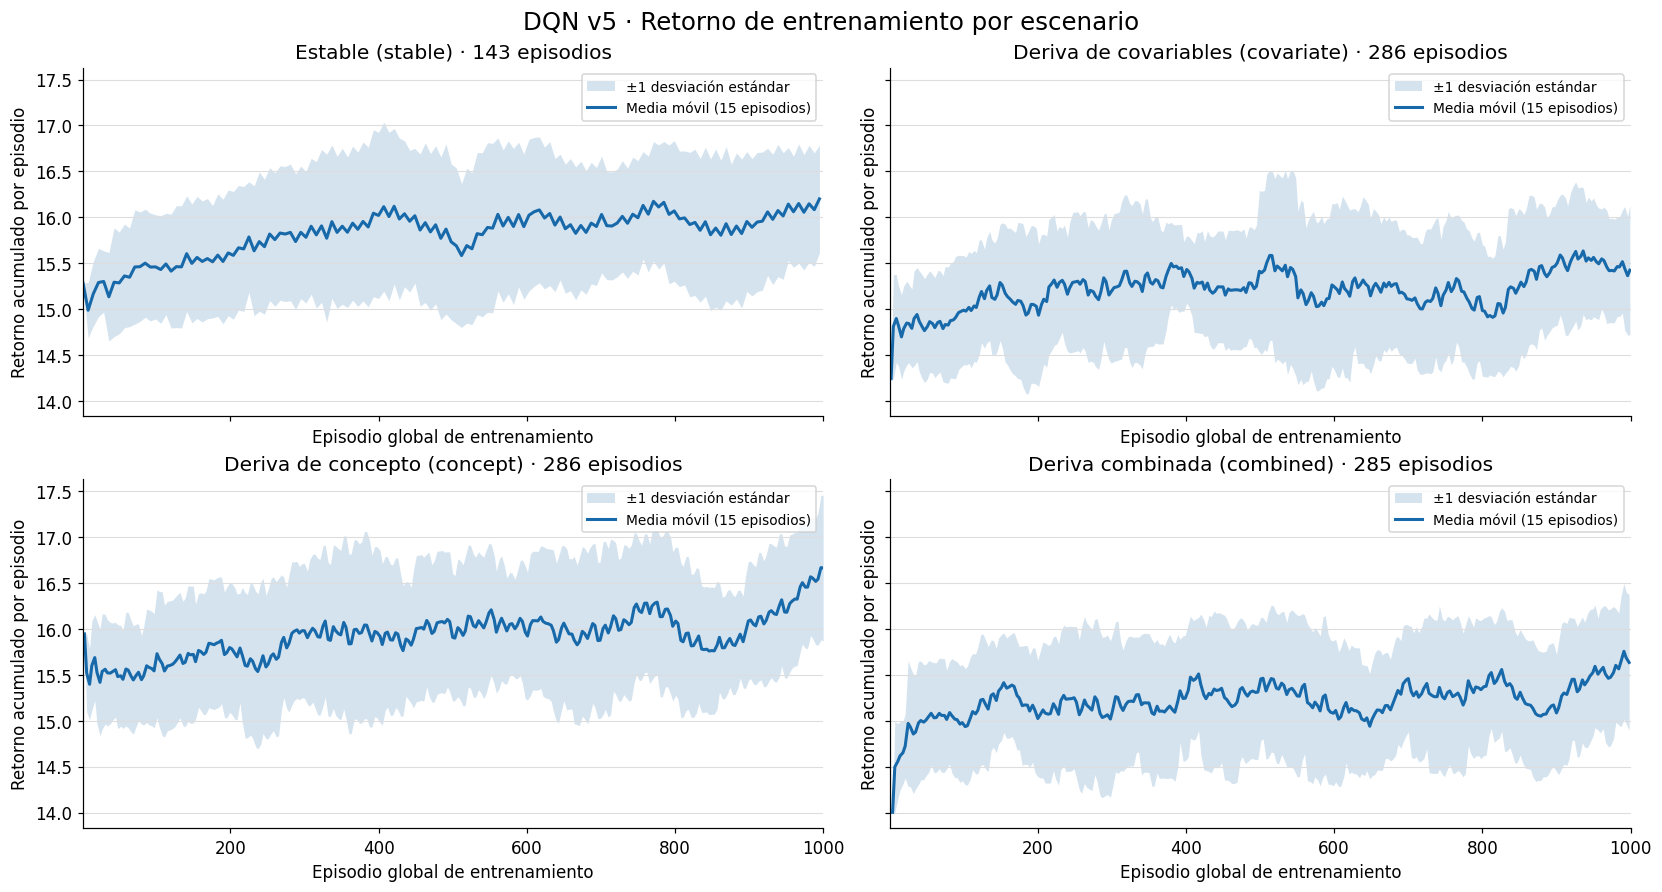

In [ ]:
assert isinstance(WINDOW, int) and WINDOW >= 1
fig, axes = plt.subplots(
    2, 2, figsize=(15, 8), sharex=True, sharey=True, layout="constrained"
)
for ax, (name, label) in zip(axes.flat, scenario_labels.items()):
    rows = groups[name]
    rolling = rows["train_return"].rolling(window=WINDOW, min_periods=1)
    mean_return = rolling.mean()
    std_return = rolling.std(ddof=0)
    lower = mean_return - std_return
    upper = mean_return + std_return
    ax.fill_between(
        rows["episode"],
        lower,
        upper,
        color="#1769AA",
        alpha=0.18,
        linewidth=0,
        label="±1 desviación estándar",
    )
    ax.plot(
        rows["episode"],
        mean_return,
        color="#1769AA",
        linewidth=2,
        label=f"Media móvil ({WINDOW} episodios)",
    )
    ax.set_title(f"{label} · {len(rows)} episodios")
    ax.set_xlabel("Episodio global de entrenamiento")
    ax.set_ylabel("Retorno acumulado por episodio")
    ax.set_xlim(history["episode"].min(), history["episode"].max())
    ax.grid(axis="y", color="#DDDDDD", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", fontsize=9)

    # Comprobar la primera ventana completa contra el cálculo directo.
    end = min(WINDOW, len(rows))
    sample = rows["train_return"].iloc[:end].to_numpy()
    np.testing.assert_allclose(mean_return.iloc[end - 1], sample.mean())
    np.testing.assert_allclose(std_return.iloc[end - 1], sample.std(ddof=0))
    assert np.isfinite(np.column_stack([mean_return, lower, upper])).all()
    assert (lower <= mean_return).all() and (mean_return <= upper).all()
    np.testing.assert_array_equal(ax.lines[0].get_xdata(), rows["episode"])
    np.testing.assert_allclose(ax.lines[0].get_ydata(), mean_return)

assert sum(len(ax.lines[0].get_xdata()) for ax in axes.flat) == len(history)
fig.suptitle("DQN v5 · Retorno de entrenamiento por escenario", fontsize=16)
plt.show()

## Lectura

La frecuencia de muestreo difiere: 143 episodios estables, 286 de covariables,
286 de concepto y 285 combinados. Los cuatro paneles reúnen los 1000 episodios.
La variabilidad dentro de cada panel incluye los cambios de exploración,
inicio e intensidad de deriva del entrenamiento; estas curvas por sí solas
no establecen convergencia ni superioridad frente a otras políticas.
